# TP MDP : Snake

Le code est dans `snake.py`, `players.py` et `simulation.py`, les tests dans `test_snake.py`. Les figures sont enregistrées dans `figures/`.

In [ ]:
import inspect
import os
import random
import textwrap

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Code

from snake import ShortSnake, UP, DOWN, LEFT, RIGHT, NAMES
from players import GreedyPlayer
from simulation import play, simulate

SEED = 42
SIZE = 5  # grille 5 x 5 pour les expériences (voir 3.10)
random.seed(SEED)
os.makedirs("figures", exist_ok=True)

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#8a5cd1", "#d1495b"]
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#888888",
    "axes.grid": True,
    "grid.color": "#e5e5e5",
    "grid.linewidth": 0.8,
    "lines.linewidth": 1.6,
    "font.size": 10,
})

def show(obj):
    return Code(textwrap.dedent(inspect.getsource(obj)), language="python")

def moving_average(x, w):
    return np.convolve(x, np.ones(w) / w, mode="valid")

## Code commun

Le jeu `ShortSnake` (Ex 1). `move` renvoie la récompense de l'étape, c'est-à-dire la variation du score.

In [ ]:
random.seed(SEED)
game = ShortSnake(10)
print(game)

. . . . . . . . . .
. . . . . . . . . .
. . . . . . . . . .
. . . . . . . . . .
. . . . . . . . . .
. . . . . @ . . . .
. . . . . . . . . .
. . . . . . . . . .
. . * . . . . . . .
. . . . . . . . . .
score : 0


## Exercice 3 — Q-Learning

### 3.1 — `save_state`

L'état est le tuple (corps du serpent, direction, position du fruit). Le score n'en fait pas partie.

In [ ]:
show(ShortSnake.save_state)

def save_state(self):
    return (tuple(self.body), self.snake_dir, self.fruit_pos)

In [ ]:
random.seed(SEED)
game = ShortSnake(10)
state = game.save_state()
print("état :", state)
print("type :", type(state).__name__, "| hashable :", hash(state) is not None)

état : (((5, 5),), (0, 1), (8, 2))
type : tuple | hashable : True


### 3.2 — `restore_state`

In [ ]:
show(ShortSnake.restore_state)

def restore_state(self, state):
    body, self.snake_dir, self.fruit_pos = state
    self.body = list(body)
    self.snake_pos = self.body[0]

In [ ]:
saved = game.save_state()
for d in [UP, UP, LEFT, None, DOWN]:
    game.move(d)
print("après 5 coups :", game.save_state())
game.restore_state(saved)
print("après restore :", game.save_state())
print("identique à l'état sauvegardé :", game.save_state() == saved)

après 5 coups : (((4, 3),), (1, 0), (8, 2))
après restore : (((5, 5),), (0, 1), (8, 2))
identique à l'état sauvegardé : True


### 3.3 — Formule du Q-Learning

$$Q(S_t, A_t) \leftarrow Q(S_t, A_t) + \alpha \left[ R_{t+1} + \gamma \max_a Q(S_{t+1}, a) - Q(S_t, A_t) \right]$$

On garde le pas du TP précédent : α = 1 / N(s, a).

### 3.4 – 3.6 — Constructeur

`GreedyPlayer` reçoit le jeu (`game`), ε et γ. Q (`action_values`) et N (`eval_count`) sont des dictionnaires indexés par des paires (état, action) : une paire absente vaut 0.

In [ ]:
show(GreedyPlayer.__init__)

def __init__(self, game, eps=0.1, gamma=0.5):
    self.game = game
    self.eps = eps
    self.gamma = gamma
    self.action_values = {}  # Q[(état, action)], 0 par défaut
    self.eval_count = {}     # N[(état, action)]
    self.last_state = None

In [ ]:
show(GreedyPlayer.q)

def q(self, state, action):
    return self.action_values.get((state, action), 0.0)

In [ ]:
random.seed(SEED)
game = ShortSnake(10)
player = GreedyPlayer(game, eps=0.1, gamma=0.5)
print("eps =", player.eps, "| gamma =", player.gamma)
print("action_values =", player.action_values, "| eval_count =", player.eval_count)
print("Q(état actuel, haut) =", player.q(game.save_state(), UP))

eps = 0.1 | gamma = 0.5
action_values = {} | eval_count = {}
Q(état actuel, haut) = 0.0


### 3.7 — `_greedy_action` qui tient compte de l'état

On lit l'état actuel, puis on prend l'action de plus grande valeur Q(état, a) parmi les actions autorisées (pas de demi-tour), au hasard en cas d'égalité.

In [ ]:
show(GreedyPlayer.get_action)

def get_action(self):
    self.last_state = self.game.save_state()
    explore = random.random() < self.eps
    if explore:
        return self._random_action()
    return self._greedy_action()

In [ ]:
show(GreedyPlayer._greedy_action)

def _greedy_action(self):
    state = self.game.save_state()
    actions = self.game.actions()
    values = [self.q(state, a) for a in actions]
    best = max(values)
    return random.choice([a for a, v in zip(actions, values) if v == best])

In [ ]:
show(GreedyPlayer._random_action)

def _random_action(self):
    return random.choice(self.game.actions())

In [ ]:
random.seed(SEED)
game = ShortSnake(10)
player = GreedyPlayer(game, eps=0)
s = game.save_state()
print("direction :", NAMES[game.snake_dir], "| actions autorisées :",
      [NAMES[a] for a in game.actions()])
print("Q vide, 10 appels    :", [NAMES[player._greedy_action()] for _ in range(10)])

player.action_values[(s, DOWN)] = 3.0
player.action_values[(s, UP)] = 1.0
print("Q(s, bas) = 3, 10 appels :", [NAMES[player._greedy_action()] for _ in range(10)])

game.move(UP)  # autre état : Q est vide pour lui
print("dans l'état suivant  :", [NAMES[player._greedy_action()] for _ in range(10)])

direction : droite | actions autorisées : ['haut', 'droite', 'bas']
Q vide, 10 appels    : ['haut', 'haut', 'bas', 'droite', 'haut', 'haut', 'haut', 'bas', 'haut', 'bas']
Q(s, bas) = 3, 10 appels : ['bas', 'bas', 'bas', 'bas', 'bas', 'bas', 'bas', 'bas', 'bas', 'bas']
dans l'état suivant  : ['haut', 'droite', 'gauche', 'droite', 'haut', 'haut', 'gauche', 'droite', 'droite', 'droite']


### 3.8 — `reward` : mise à jour du Q-Learning (γ = 0,5)

`reward` est appelée juste après `game.move(action)`, le jeu est donc déjà dans l'état suivant s'.

In [ ]:
show(GreedyPlayer.reward)

def reward(self, action, value):
    # appelée après game.move(action) : le jeu est déjà dans l'état suivant
    key = (self.last_state, action)
    next_state = self.game.save_state()
    best_next = max(self.q(next_state, a) for a in self.game.actions())
    target = value + self.gamma * best_next

    self.eval_count[key] = self.eval_count.get(key, 0) + 1
    q = self.action_values.get(key, 0.0)
    self.action_values[key] = q + (target - q) / self.eval_count[key]

In [ ]:
game = ShortSnake(10)
game.restore_state((((5, 9),), RIGHT, (0, 0)))  # au bord droit, on va à droite
player = GreedyPlayer(game, eps=0, gamma=0.5)
s = game.save_state()
s2 = (((5, 0),), RIGHT, (0, 0))
player.action_values[(s2, UP)] = 4.0  # on fixe max Q(s', a') = 4

player.last_state = s
r = game.move(RIGHT)
player.reward(RIGHT, r)
print("récompense =", r)
print("Q(s, droite) =", player.action_values[(s, RIGHT)],
      "| attendu : 0 + 1/1 * (-10 + 0.5 * 4 - 0) =", -10 + 0.5 * 4)

# 2e passage avec cette fois max Q(s', a') = 0 : cible = -10
player.action_values[(s2, UP)] = 0.0
game.restore_state(s)
player.last_state = s
player.reward(RIGHT, game.move(RIGHT))
print("après 2 passages : Q(s, droite) =", player.action_values[(s, RIGHT)],
      "| N =", player.eval_count[(s, RIGHT)], "| attendu : -8 + 1/2 * (-10 - (-8)) =", -8 + (-10 + 8) / 2)

récompense = -10
Q(s, droite) = -8.0 | attendu : 0 + 1/1 * (-10 + 0.5 * 4 - 0) = -8.0
après 2 passages : Q(s, droite) = -9.0 | N = 2 | attendu : -8 + 1/2 * (-10 - (-8)) = -9.0


### Tests automatiques

`test_snake.py` vérifie le jeu (bords, fruit, demi-tour, save/restore, serpent de taille 2 et 5) et le joueur (formule du Q-Learning, choix greedy, exploration, apprentissage).

In [ ]:
import sys
!"{sys.executable}" -m pytest -v --color=no -p no:cacheprovider test_snake.py | grep -E "PASSED|FAILED|ERROR|passed|failed"

test_snake.py::test_depart_au_milieu PASSED                              [  6%]
test_snake.py::test_none_continue_tout_droit PASSED                      [ 12%]
test_snake.py::test_pas_de_demi_tour PASSED                              [ 18%]
test_snake.py::test_bord_traverse_et_perd_10 PASSED                      [ 25%]
test_snake.py::test_fruit_rapporte_10_et_reapparait PASSED               [ 31%]
test_snake.py::test_fruit_juste_apres_le_bord PASSED                     [ 37%]
test_snake.py::test_save_restore PASSED                                  [ 43%]
test_snake.py::test_serpent_de_taille_2 PASSED                           [ 50%]
test_snake.py::test_auto_intersection PASSED                             [ 56%]
test_snake.py::test_q_learning_mise_a_jour PASSED                        [ 62%]
test_snake.py::test_greedy_prend_la_meilleure_action_de_l_etat PASSED    [ 68%]
test_snake.py::test_greedy_egalite_au_hasard PASSED                      [ 75%]
test_snake.py::test_actions_aleatoires_l

test_snake.py::test_proportion_exploration PASSED                        [ 87%]


test_snake.py::test_l_ia_apprend PASSED                                  [ 93%]


test_snake.py::test_play_renvoie_le_score PASSED                         [100%]
============================== 16 passed in 1.34s ==============================


### 3.10 — Récompense au cours des 1000 premières étapes

Boucle de jeu (programme principal, 3.9) :

In [ ]:
show(play)

def play(game, player, steps):
    """Fait jouer `player` sur `game` pendant `steps` étapes.

    Renvoie la récompense obtenue à chaque étape.
    """
    rewards = np.zeros(steps)
    for t in range(steps):
        action = player.get_action()
        value = game.move(action)
        player.reward(action, value)
        rewards[t] = value
    return rewards

In [ ]:
random.seed(SEED)
game = ShortSnake(SIZE)
player = GreedyPlayer(game, eps=0.1, gamma=0.5)
rewards = play(game, player, 1000)

for name, part in [("100 premières", rewards[:100]), ("100 dernières", rewards[-100:])]:
    print(f"{name} étapes : récompense moyenne = {part.mean():+.2f}"
          f" | fruits = {(part > 0).sum()} | bords = {(part < 0).sum()}")
print("score final :", game.score)

100 premières étapes : récompense moyenne = -1.50 | fruits = 4 | bords = 19
100 dernières étapes : récompense moyenne = -1.20 | fruits = 4 | bords = 16
score final : -1190


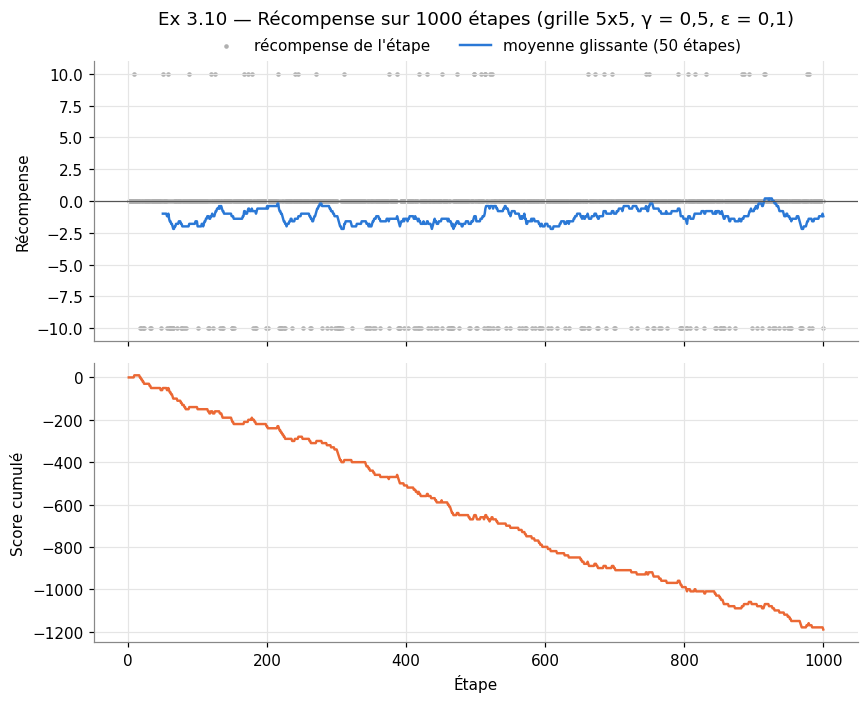

In [ ]:
def plot_run(rewards, title, path, w=50):
    steps = np.arange(1, len(rewards) + 1)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6.5), sharex=True)
    ax1.scatter(steps, rewards, s=4, color="#b0b0b0", label="récompense de l'étape")
    ax1.plot(steps[w - 1:], moving_average(rewards, w), color=COLORS[0],
             label=f"moyenne glissante ({w} étapes)")
    ax1.axhline(0, color="#555555", linewidth=0.8)
    ax1.set_ylabel("Récompense")
    ax1.set_title(title, pad=24)
    ax1.legend(frameon=False, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 0.98))
    ax2.plot(steps, np.cumsum(rewards), color=COLORS[1])
    ax2.set_ylabel("Score cumulé")
    ax2.set_xlabel("Étape")
    fig.tight_layout()
    fig.savefig(path)
    plt.show()

plot_run(rewards, f"Ex 3.10 — Récompense sur 1000 étapes (grille {SIZE}x{SIZE}, γ = 0,5, ε = 0,1)",
         "figures/ex3_10_recompense_1000.png")

In [ ]:
# Pourquoi une grille 5 x 5 : nombre de paires (état, action) vues en 1000 étapes
for size in (5, 10):
    random.seed(SEED)
    game = ShortSnake(size)
    player = GreedyPlayer(game, eps=0.1, gamma=0.5)
    play(game, player, 1000)
    n_states = size * size * 4 * (size * size - 1)
    seen = len(player.eval_count)
    revisited = sum(c > 1 for c in player.eval_count.values())
    print(f"{size:2d} x {size:<2d} : {n_states:6d} états, {3 * n_states:6d} paires (état, action)"
          f" | paires vues : {seen} | vues plus d'une fois : {revisited}")

 5 x 5  :   2400 états,   7200 paires (état, action) | paires vues : 904 | vues plus d'une fois : 85
10 x 10 :  39600 états, 118800 paires (état, action) | paires vues : 929 | vues plus d'une fois : 66


## Exercice 4 (Bonus) — Serpent de taille 2

### 4.5 — Mêmes graphiques avec un serpent de taille 2

Le serpent de taille 2 utilise la même classe (`ShortSnake(n, length=2)`) et le même `GreedyPlayer` : `save_state` renvoie maintenant les 2 cases du corps.

In [ ]:
random.seed(SEED)
game2 = ShortSnake(SIZE, length=2)
print(game2)
print("état :", game2.save_state())

player2 = GreedyPlayer(game2, eps=0.1, gamma=0.5)
rewards2 = play(game2, player2, 1000)
print("score après 1000 étapes :", game2.score)

. . . . .
. . . . .
. o @ . .
. . . . .
. . * . .
score : 0
état : (((2, 2), (2, 1)), (0, 1), (4, 2))
score après 1000 étapes : -1370


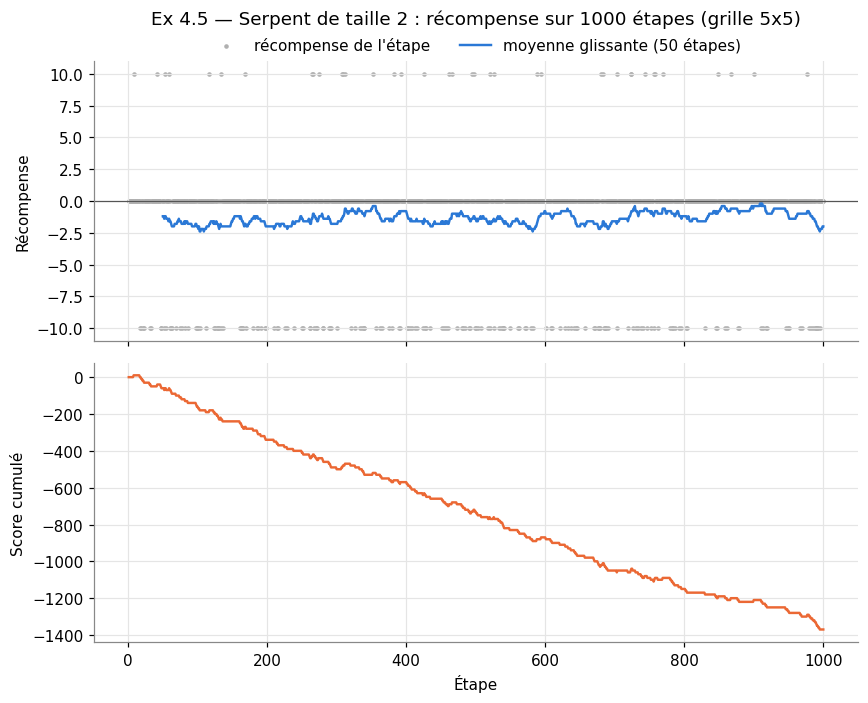

In [ ]:
plot_run(rewards2, f"Ex 4.5 — Serpent de taille 2 : récompense sur 1000 étapes (grille {SIZE}x{SIZE})",
         "figures/ex4_5_taille2_1000.png")

Moyenne sur 200 parties de 10 000 étapes, taille 1 contre taille 2 (γ = 0,5, ε = 0,1) :

In [ ]:
show(simulate)

def simulate(runs, steps, size=10, length=1, eps=0.1, gamma=0.5):
    """Relance `runs` parties indépendantes, renvoie un tableau (runs, steps)."""
    all_rewards = np.zeros((runs, steps))
    for r in range(runs):
        game = ShortSnake(size, length=length)
        player = GreedyPlayer(game, eps=eps, gamma=gamma)
        all_rewards[r] = play(game, player, steps)
    return all_rewards

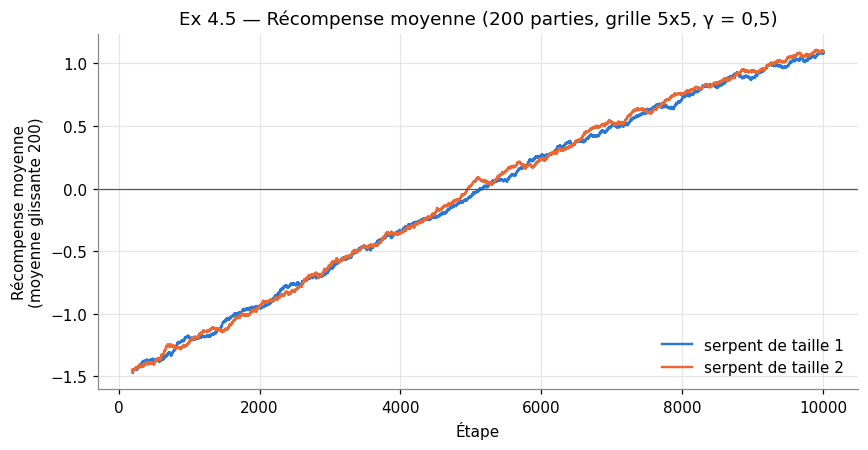

In [ ]:
RUNS, STEPS = 200, 10_000
random.seed(SEED)
by_length = {L: simulate(RUNS, STEPS, size=SIZE, length=L) for L in (1, 2)}

fig, ax = plt.subplots(figsize=(8, 4.2))
w = 200
for i, (L, R) in enumerate(by_length.items()):
    mean = R.mean(axis=0)
    ax.plot(np.arange(w, STEPS + 1), moving_average(mean, w), color=COLORS[i],
            label=f"serpent de taille {L}")
ax.axhline(0, color="#555555", linewidth=0.8)
ax.set_title(f"Ex 4.5 — Récompense moyenne ({RUNS} parties, grille {SIZE}x{SIZE}, γ = 0,5)")
ax.set_xlabel("Étape")
ax.set_ylabel(f"Récompense moyenne\n(moyenne glissante {w})")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig("figures/ex4_5_taille1_vs_taille2.png")
plt.show()

In [ ]:
print("récompense moyenne par tranche de 2000 étapes")
print("étapes       " + "".join(f"{f'{a}-{a + 2000}':>12s}" for a in range(0, STEPS, 2000)))
for L, R in by_length.items():
    mean = R.mean(axis=0)
    print(f"taille {L}     " + "".join(f"{mean[a:a + 2000].mean():12.2f}" for a in range(0, STEPS, 2000)))
for L, R in by_length.items():
    m = R.mean(axis=0)
    cross = np.argmax(moving_average(m, 200) > 0) + 200
    print(f"taille {L} : la récompense moyenne devient positive vers l'étape {cross}")

récompense moyenne par tranche de 2000 étapes
étapes             0-2000   2000-4000   4000-6000   6000-8000  8000-10000
taille 1            -1.19       -0.60       -0.02        0.51        0.94
taille 2            -1.20       -0.60        0.00        0.54        0.96
taille 1 : la récompense moyenne devient positive vers l'étape 5124
taille 2 : la récompense moyenne devient positive vers l'étape 4958


Mêmes facteurs d'actualisation qu'en 3.12, avec le serpent de taille 2 (100 parties de 10 000 étapes) :

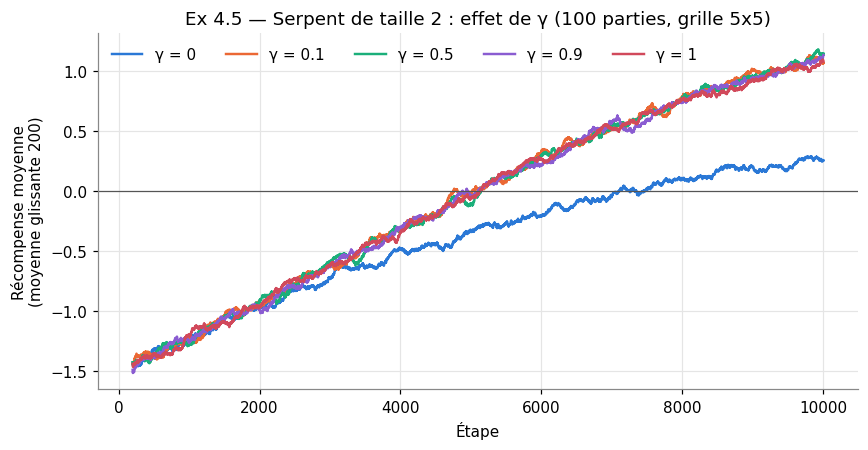

γ = 0    | 1000 premières : -1.33 | 1000 dernières : +0.23
γ = 0.1  | 1000 premières : -1.33 | 1000 dernières : +1.04
γ = 0.5  | 1000 premières : -1.33 | 1000 dernières : +1.06
γ = 0.9  | 1000 premières : -1.35 | 1000 dernières : +1.04
γ = 1    | 1000 premières : -1.34 | 1000 dernières : +1.02


In [ ]:
GAMMAS = [0, 0.1, 0.5, 0.9, 1]
random.seed(SEED)
by_gamma = {g: simulate(100, STEPS, size=SIZE, length=2, gamma=g).mean(axis=0) for g in GAMMAS}

fig, ax = plt.subplots(figsize=(8, 4.2))
for i, (g, mean) in enumerate(by_gamma.items()):
    ax.plot(np.arange(w, STEPS + 1), moving_average(mean, w), color=COLORS[i], label=f"γ = {g}")
ax.axhline(0, color="#555555", linewidth=0.8)
ax.set_title(f"Ex 4.5 — Serpent de taille 2 : effet de γ (100 parties, grille {SIZE}x{SIZE})")
ax.set_xlabel("Étape")
ax.set_ylabel(f"Récompense moyenne\n(moyenne glissante {w})")
ax.legend(frameon=False, loc="upper left", ncol=5)
fig.tight_layout()
fig.savefig("figures/ex4_5_taille2_gammas.png")
plt.show()

for g, mean in by_gamma.items():
    print(f"γ = {g:<4} | 1000 premières : {mean[:1000].mean():+.2f}"
          f" | 1000 dernières : {mean[-1000:].mean():+.2f}")

### 4.6 — Vérification sur la grille 10 x 10

10 parties de 100 000 étapes par taille.

In [ ]:
random.seed(SEED)
for L in (1, 2):
    m = simulate(10, 100_000, size=10, length=L).mean(axis=0)
    print(f"taille {L} : " + " ".join(f"{m[a:a + 20_000].mean():+.2f}" for a in range(0, 100_000, 20_000))
          + "   (moyenne par tranche de 20 000 étapes)")

taille 1 : -0.78 -0.66 -0.55 -0.44 -0.33   (moyenne par tranche de 20 000 étapes)


taille 2 : -0.78 -0.67 -0.55 -0.44 -0.33   (moyenne par tranche de 20 000 étapes)
